# 1) Análise Exploratória de Dados (EDA) — VisDrone2019-DET e Galeria de Referência

Este notebook apresenta a **Análise Exploratória de Dados (EDA)** reprodutível do dataset público de imagens aéreas **VisDrone2019-DET** (`train` + `val`) e estabelece a ponte metodológica com a **Galeria de Referência Simulada** (`data/reference_dataset/`), preparando a base para a validação final no dataset da competição (`drone-forest-vehicles`).

### Objetivos da Análise
1. **Frequência e Dominância de Classes:** Quantificar a distribuição das 10 classes do VisDrone em **7.019 imagens aéreas** (**381.963 bounding boxes válidas**), destacando as **4 classes de veículos-alvo do detector** (`car`, `van`, `truck`, `bus`) frente às demais categorias (`pedestrian`, `people`, `motor`, `bicycle`, `tricycle`, `awning-tricycle`).
2. **Escala dos Objetos e Geometria das Bounding Boxes:** Investigar a área relativa das caixas (`box_area / image_area`), a distribuição por escala absoluta segundo o critério COCO (*Small* `< 32² px²`, *Medium* `32²–96² px²`, *Large* `≥ 96² px²`) e a razão de aspecto (`w / h`) em tomada aérea.
3. **Resoluções de Imagem, Densidade por Cena e Distribuição Espacial:** Avaliar as resoluções nativas, o grau de aglomeração (*crowding* de objetos e veículos por imagem) e o mapa de calor espacial dos centros das detecções.
4. **Oclusão, Truncamento e Regiões Ignoradas:** Explorar os metadados nativos do formato VisDrone (`occlusion`, `truncation` e categorias ignoradas `0`/`11`).
5. **Cenas Representativas e Inferência Qualitativa (YOLOv8s):** Visualizar cenas reais anotadas e inspecionar o comportamento do checkpoint pré-treinado `dronefreak/visdrone-yolov8s` configurado em `configs/default.yaml`.
6. **Ponte com a Galeria de Referência Simulada (3D):** Contrastar a taxonomia ampla do detector (`car`, `van`, `truck`, `bus`) com os **5 modelos operacionais específicos** (`arquus_vt4`, `panhard_vbl`, `renault_ccfm`, `renault_gbc180`, `vltt`) que serão reconhecidos via embeddings `EfficientNet-B3`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as IPyImage, display

from vehicle_recognition.eda_visdrone import load_visdrone_dataframe, run_visdrone_eda

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "configs/default.yaml").is_file():
    REPO_ROOT = REPO_ROOT.parent

OUT_DIR = REPO_ROOT / "outputs/eda_visdrone"
FIG_DIR = OUT_DIR / "figures"
SUMMARY_PATH = OUT_DIR / "eda_visdrone_summary.json"

with SUMMARY_PATH.open(encoding="utf-8") as f:
    eda_summary = json.load(f)

print(f"Repositório: {REPO_ROOT}")
print(f"Dataset analisado: {eda_summary['dataset']}")
print(f"Total de imagens (Train + Val): {eda_summary['total_images']:,} {eda_summary['splits_image_count']}")
print(f"Total de bounding boxes YOLO válidas: {eda_summary['class_frequencies']['total_valid_boxes']:,}")
print(f"Total de veículos-alvo (car, van, truck, bus): {eda_summary['class_frequencies']['total_vehicle_boxes']:,} ({eda_summary['class_frequencies']['vehicle_share_pct']}%)")

Repositório: c:\Users\Windows\Downloads\drone-vehicle-recognition-main\drone-vehicle-recognition-main
Dataset analisado: VisDrone2019-DET (train + val)
Total de imagens (Train + Val): 7,019 {'train': 6471, 'val': 548}
Total de bounding boxes YOLO válidas: 381,963
Total de veículos-alvo (car, van, truck, bus): 205,663 (53.84%)

---
## 1. Distribuição de Frequência das 10 Classes (Destaque para Veículos)

No pipeline proposto (`configs/default.yaml`), o detector YOLOv8s localiza veículos filtrando as classes **`car`**, **`van`**, **`truck`** e **`bus`** (resolvidas pelo nome no checkpoint), enquanto o classificador por similaridade (`EfficientNet-B3`) identifica o modelo operacional específico a partir do recorte (*crop*).

### Principais Constatações Estatísticas:
- **Dominância de Veículos:** Das **381.963** anotações válidas (`train` + `val`), **205.663 (53,84%)** pertencem às 4 classes de veículos-alvo (`car`, `van`, `truck`, `bus`).
- **Desbalanceamento Interno entre Veículos:**
  - **`car`** é a classe majoritária absoluta do VisDrone, com **158.930 instâncias** (**41,61%** de todo o dataset e **77,28%** de todos os veículos), estando presente em **94,71%** das imagens.
  - **`van`** soma **26.931 instâncias** (**7,05%** do total | **13,09%** dos veículos), presente em **76,49%** das imagens.
  - **`truck`** soma **13.625 instâncias** (**3,57%** do total | **6,62%** dos veículos), presente em **54,38%** das imagens.
  - **`bus`** soma **6.177 instâncias** (**1,62%** do total | **3,00%** dos veículos), presente em **30,69%** das imagens.
- **Classes Não-Veiculares Relevantes:** `pedestrian` (23,09%), `motor` (9,04%) e `people` (8,43%) respondem juntos por 40,56% das caixas. Isso reforça a importância da filtragem explícita por `vehicle_classes: [car, van, truck, bus]` na etapa de detecção para evitar que pedestres ou motocicletas sejam enviados ao extrator `EfficientNet-B3`.

class_name,is_vehicle,train_count,val_count,total_count,pct_of_total,pct_of_vehicles,image_presence_pct
car,True,144866,14064,158930,41.61,77.28,94.71
pedestrian,False,79337,8844,88181,23.09,NaN,83.86
motor,False,29647,4886,34533,9.04,NaN,67.27
people,False,27059,5125,32184,8.43,NaN,63.10
van,True,24956,1975,26931,7.05,13.09,76.49
truck,True,12875,750,13625,3.57,6.62,54.38
bicycle,False,10480,1287,11767,3.08,NaN,44.44
bus,True,5926,251,6177,1.62,3.00,30.69
tricycle,False,4812,1045,5857,1.53,NaN,28.85
awning-tricycle,False,3246,532,3778,0.99,NaN,19.53


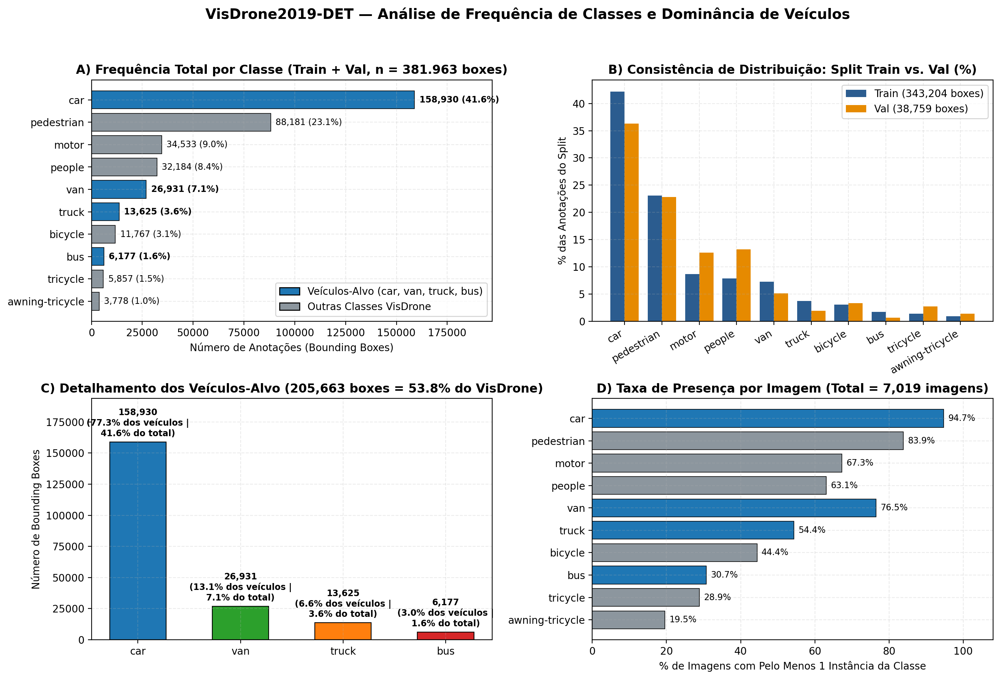

In [2]:
freq_df = pd.read_csv(OUT_DIR / "visdrone_class_frequencies.csv")
display(freq_df.style.format({
    "train_count": "{:,}",
    "val_count": "{:,}",
    "total_count": "{:,}",
    "pct_of_total": "{:.2f}%",
    "pct_of_vehicles": lambda v: "-" if pd.isna(v) else f"{v:.2f}%",
    "image_presence_pct": "{:.2f}%",
}))
display(IPyImage(filename=str(FIG_DIR / "01_class_frequencies.png")))

---
## 2. Tamanho das Bounding Boxes, Escalas COCO e Razão de Aspecto

Imagens capturadas por drones apresentam grandes variações de altitude e ângulo de visada (oblíquo vs. nadir), resultando em objetos de pequena escala.

### Principais Constatações:
- **Predominância de Objetos Pequenos (Critério COCO `< 32×32 px`):**
  - Considerando todas as 10 classes, **61,29%** das caixas são **Small (`< 32² px²`)**, **33,46%** são **Medium (`32²–96² px²`)** e apenas **5,25%** são **Large (`≥ 96² px²`)**.
  - Considerando apenas os **veículos-alvo (`car`, `van`, `truck`, `bus`)**, **45,91%** são *Small*, **44,95%** são *Medium* e **9,14%** são *Large*.
- **Dimensões Medianas dos Veículos:**
  - `car`: mediana de **38 × 29 px** (área relativa mediana de **0,076%** da imagem; razão de aspecto mediana `w/h = 1,25`).
  - `van`: mediana de **39 × 34 px** (área relativa mediana de **0,093%**; `w/h = 1,12`).
  - `truck`: mediana de **49 × 43 px** (área relativa mediana de **0,150%**; `w/h = 1,04`).
  - `bus`: mediana de **48 × 47 px** (área relativa mediana de **0,185%**; `w/h = 0,94`).
- **Implicação Direta para o Pipeline:** Como quase metade dos veículos tem área inferior a `32×32` pixels na resolução nativa, realizar inferência do YOLO em **`image_size: 1280`** (conforme configurado em `configs/default.yaml`, em vez do padrão `640`) e aplicar margem de recorte (`crop_margin_pixels: 10`) é essencial para preservar detalhes visuais antes do redimensionamento para o `EfficientNet-B3`.

class_name,median_rel_area_pct,mean_rel_area_pct,p90_rel_area_pct,median_width_px,median_height_px,median_aspect_ratio,small_pct,medium_pct,large_pct
car,0.0761,0.2082,0.5167,38.0,29.0,1.25,48.26,43.73,8.00
van,0.0928,0.2378,0.5829,39.0,34.0,1.12,43.34,46.27,10.39
truck,0.1500,0.4325,1.0255,49.0,43.0,1.04,31.36,52.10,16.54
bus,0.1849,0.5079,1.1864,48.0,47.0,0.94,28.70,54.59,16.71
pedestrian,0.0239,0.0481,0.1117,12.0,26.0,0.46,82.76,16.87,0.37
people,0.0204,0.0396,0.0871,13.0,21.0,0.62,87.42,12.25,0.32
motor,0.0359,0.0626,0.1400,21.0,23.0,0.87,75.12,24.09,0.79
bicycle,0.0360,0.0672,0.1522,23.0,25.0,0.86,69.29,29.61,1.10
tricycle,0.0887,0.1663,0.3879,35.0,31.0,1.03,47.77,48.44,3.79
awning-tricycle,0.0852,0.1740,0.3931,35.0,35.0,0.94,44.20,50.74,5.06


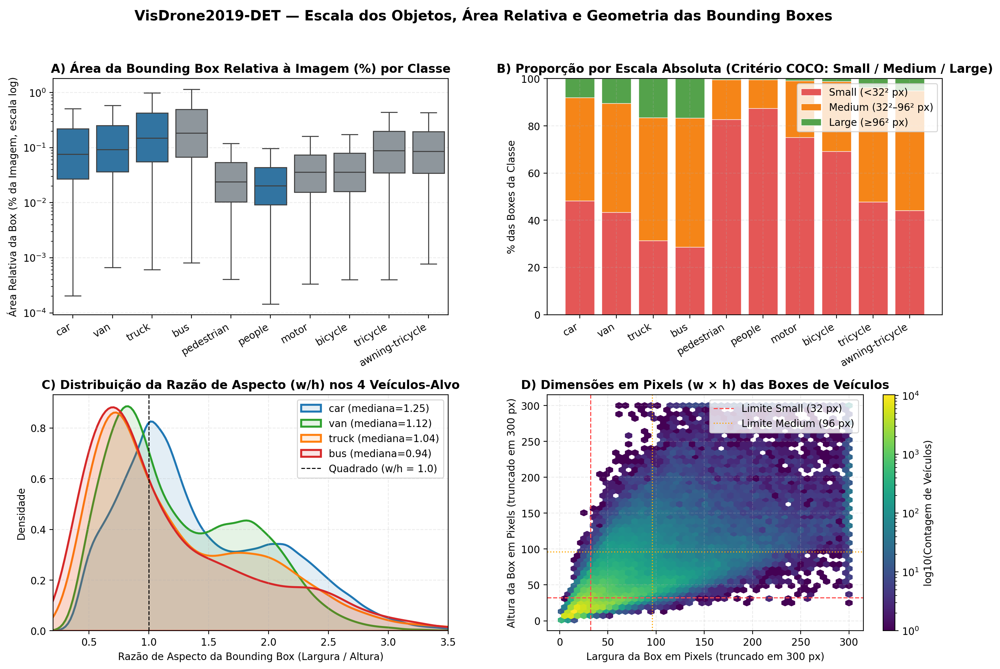

In [3]:
size_df = pd.DataFrame.from_dict(
    eda_summary["bbox_sizes_and_scales"]["per_class_box_stats"], orient="index"
).reset_index().rename(columns={"index": "class_name"})
display(size_df)
display(IPyImage(filename=str(FIG_DIR / "02_bbox_sizes_and_scales.png")))

---
## 3. Resoluções de Imagem, Densidade por Cena e Distribuição Espacial

### Principais Constatações:
- **Resoluções Nativas:** Existem **11 resoluções únicas** nos splits `train` e `val`, lideradas por **`1400×1050`** (2.498 imagens, 35,6% — proporção 4:3), **`1400×788`** (1.299 imagens, 18,5% — proporção 16:9), **`1360×765`** (1.151 imagens, 16,4%) e **`2000×1500`** (772 imagens, 11,0%).
- **Alta Densidade de Objetos por Cena (*Crowding*):**
  - Média de **54,4 objetos válidos por imagem** (mediana = **43**, percentil 90 = **106**, máximo = **902**).
  - Média de **29,3 veículos por imagem** (mediana = **22**, percentil 90 = **63**, máximo = **349**), com **95,61%** das cenas contendo ao menos um veículo.
- **Distribuição Espacial:** O mapa de calor 2D dos centros `(x_center, y_center)` mostra concentração ligeiramente superior no eixo central-superior (`y ∈ [0.15, 0.55]`), típico de câmeras de drones inclinadas em perspectiva oblíqua acompanhando vias principais, onde o fundo da cena acumula mais veículos em menor escala.

{
  "figure": "03_resolutions_and_scene_density.png",
  "unique_resolutions": 11,
  "top_resolutions": {
    "1400x1050": 2498,
    "1400x788": 1299,
    "1360x765": 1151,
    "2000x1500": 772,
    "1916x1078": 537,
    "960x540": 371
  },
  "objects_per_image": {
    "mean": 54.42,
    "median": 43.0,
    "p90": 106.0,
    "max": 902
  },
  "vehicles_per_image": {
    "mean": 29.3,
    "median": 22.0,
    "p90": 63.0,
    "max": 349,
    "images_with_vehicles_pct": 95.61
  }
}

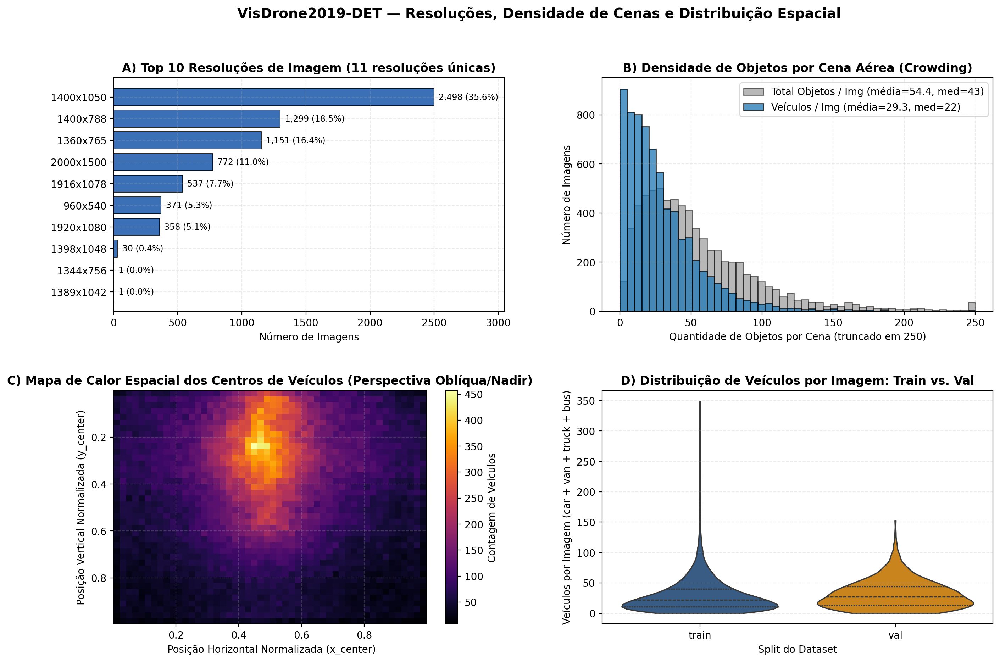

In [4]:
print("Resumo de Resoluções e Densidade:")
print(json.dumps(eda_summary["resolutions_and_density"], indent=2, ensure_ascii=False))
display(IPyImage(filename=str(FIG_DIR / "03_resolutions_and_scene_density.png")))

---
## 4. Análise de Oclusão, Truncamento e Regiões Ignoradas

As anotações brutas do VisDrone (`annotations/*.txt`) fornecem dois campos que são descartados na conversão padrão para YOLO, mas fundamentais para entender a dificuldade do domínio aéreo:
- **Grau de Oclusão (`occlusion`):**
  - Entre os veículos-alvo (`car`, `van`, `truck`, `bus`), **49,71%** não possuem oclusão (`0%`), **40,37%** apresentam **oclusão parcial (`1–50%`)** e **9,93%** sofrem **oclusão severa (`>50%`)** (por árvores, postes, edifícios ou outros veículos).
  - O painel C demonstra que veículos com oclusão parcial ou severa possuem área relativa mediana significativamente menor, agravando o desafio de extração de embeddings discriminativos.
- **Taxa de Truncamento (`truncation`):** **5,59%** dos veículos encontram-se parcialmente cortados pelas bordas da imagem, chegando a **7,2%** em caminhões (`truck`) e **8,5%** em ônibus (`bus`) devido às suas maiores dimensões físicas.
- **Regiões Ignoradas (`score=0` / categorias `0` e `11`):** Do total bruto de **393.719** linhas nas anotações, **11.756 (3,0%)** correspondem a regiões ignoradas (`ignored regions`) ou objetos fora da taxonomia (`others`), que foram devidamente filtrados na conversão para YOLO (`labels/*.txt`).

{
  "figure": "04_occlusion_and_truncation.png",
  "raw_total_rows": 393719,
  "ignored_or_others_rows": 11756,
  "vehicle_occlusion_pct": {
    "Sem oclusão (0%)": 49.71,
    "Oclusão parcial (1–50%)": 40.37,
    "Oclusão severa (>50%)": 9.93
  },
  "vehicle_truncation_pct": 5.59
}

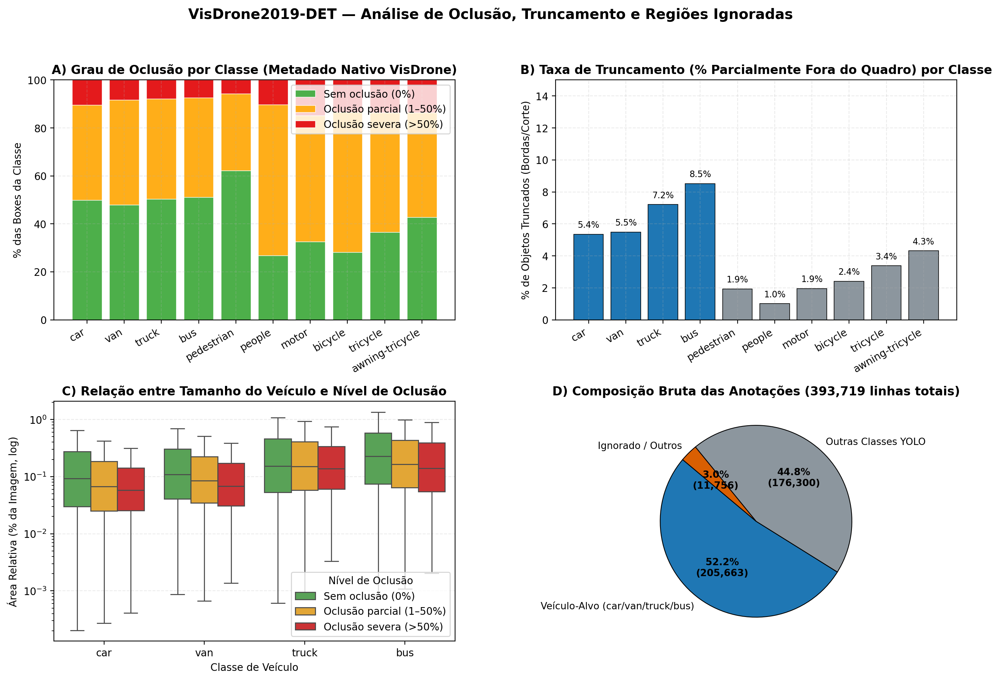

In [5]:
print("Resumo de Oclusão e Truncamento:")
print(json.dumps(eda_summary["occlusion_and_truncation"], indent=2, ensure_ascii=False))
display(IPyImage(filename=str(FIG_DIR / "04_occlusion_and_truncation.png")))

---
## 5. Cenas Representativas e Resultados Qualitativos do Detector YOLOv8s

Abaixo visualizamos:
1. **4 Cenas Representativas do Split de Validação (`05_representative_scenes.png`):** Ilustrando (1) coexistência das 4 classes de veículos, (2) tráfego urbano denso (108 veículos), (3) forte oclusão por vegetação/infraestrutura e (4) baixa altitude com veículos em maior escala.
2. **Inferência Qualitativa com `dronefreak/visdrone-yolov8s` (`06_qualitative_detector_yolov8s.png`):** Executando o checkpoint pré-treinado usando exatamente os parâmetros de `configs/default.yaml` (`vehicle_classes: [car, van, truck, bus]`, `confidence_threshold: 0.4`, `iou_threshold: 0.5`, `image_size: 1280`).
   - O mapeamento de IDs é resolvido dinamicamente a partir de `model.names` (`{3: 'car', 4: 'van', 5: 'truck', 8: 'bus'}`).
   - Em cenas de visada limpa/média altitude (`0000330_03201_d_0000816` com 30 veículos e `0000333_02157_d_0000012` com 45 veículos), o detector recupera **29/30** e **45/45** veículos com confiança média de ~0,80–0,82.
   - Já na cena `0000069_02480_d_0000007` (18 veículos fortemente ocluídos atrás de árvores no fundo da praça), o detector com `conf >= 0.4` recupera **9/18** veículos — antecipando exatamente o desafio central que encontraremos no dataset florestal (`drone-forest-vehicles`): **oclusão por copa de árvores e sombras**.

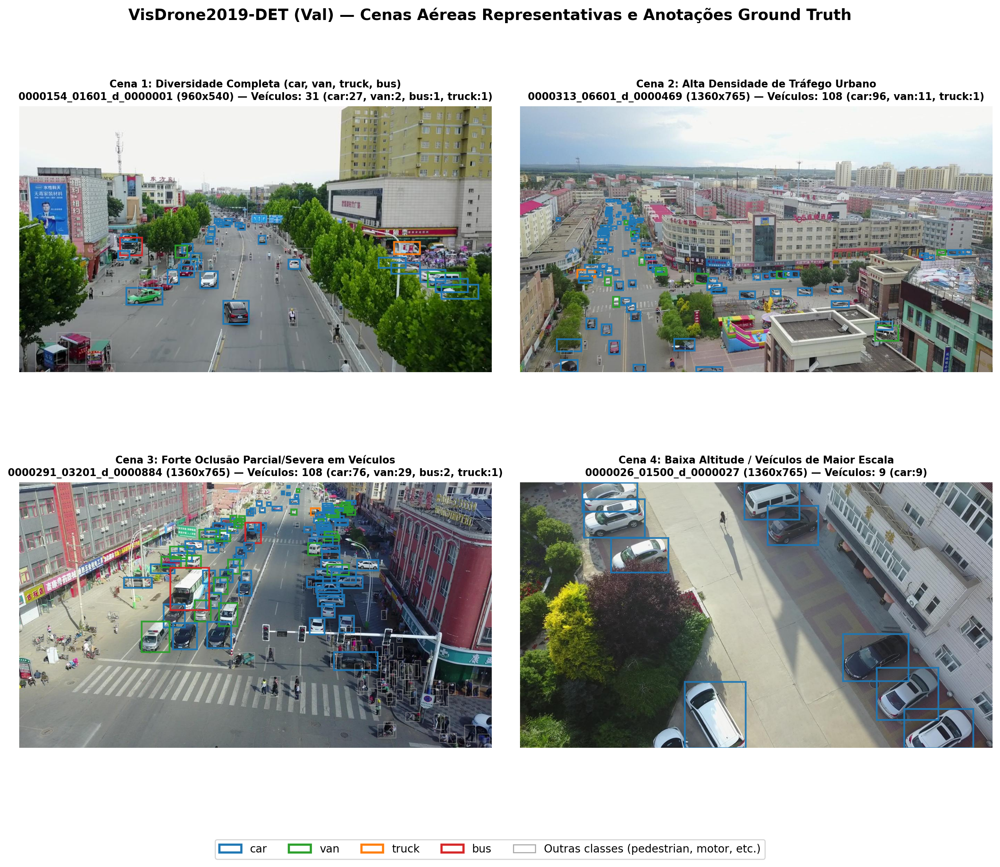

In [6]:
display(IPyImage(filename=str(FIG_DIR / "05_representative_scenes.png")))
display(IPyImage(filename=str(FIG_DIR / "06_qualitative_detector_yolov8s.png")))

{
  "figure": "06_qualitative_detector_yolov8s.png",
  "checkpoint_classes": {
    "0": "pedestrian",
    "1": "people",
    "2": "bicycle",
    "3": "car",
    "4": "van",
    "5": "truck",
    "6": "tricycle",
    "7": "awning-tricycle",
    "8": "bus",
    "9": "motor",
    "10": "others"
  },
  "filtered_vehicle_class_ids": [
    3,
    4,
    5,
    8
  ],
  "scenes_evaluated": [
    {
      "image_id": "0000069_02480_d_0000007",
      "gt_vehicles": 18,
      "detected_vehicles": 9,
      "detected_by_class": {
        "car": 9
      },
      "mean_confidence": 0.647
    },
    {
      "image_id": "0000330_03201_d_0000816",
      "gt_vehicles": 30,
      "detected_vehicles": 29,
      "detected_by_class": {
        "car": 23,
        "van": 6
      },
      "mean_confidence": 0.799
    },
    {
      "image_id": "0000333_02157_d_0000012",
      "gt_vehicles": 45,
      "detected_vehicles": 45,
      "detected_by_class": {
        "van": 8,
        "car": 37
      },
      "mean_c

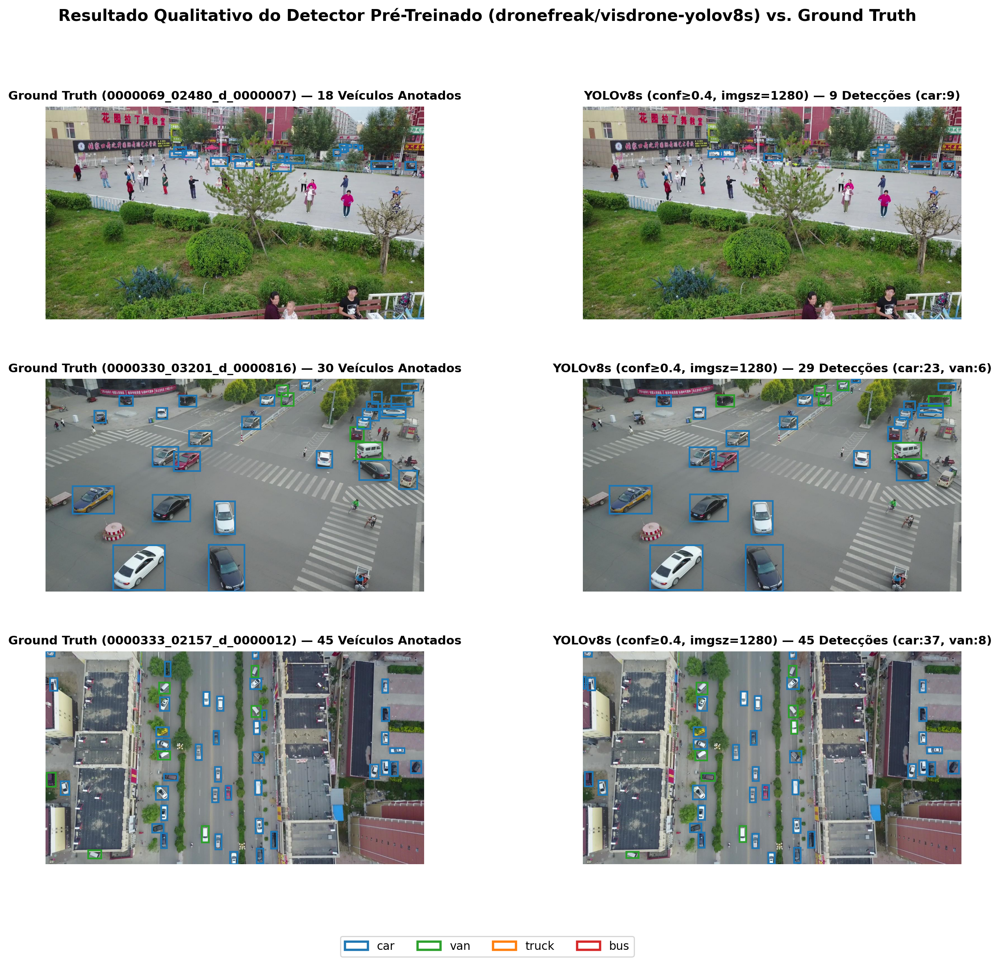

In [7]:
print("Detalhes da Inferência Qualitativa YOLOv8s:")
print(json.dumps(eda_summary["qualitative_detector"], indent=2, ensure_ascii=False))
display(IPyImage(filename=str(FIG_DIR / "06_qualitative_detector_yolov8s.png")))

---
## 6. Ponte Metodológica: Taxonomia do Detector vs. Galeria de Referência Simulada

Conforme documentado em `notebooks/README.md`, é fundamental distinguir:
1. **Dataset Genérico de Detecção (`VisDrone2019-DET`):** Ensina o detector YOLOv8s a localizar veículos em imagens aéreas usando categorias amplas (`car`, `van`, `truck`, `bus`).
2. **Galeria de Referência Simulada (`data/reference_dataset/`):** Contém **83 recortes (*crops*) gerados em simulação 3D** (58 crops base + 25 variantes aumentadas `_aug_` concentradas em `arquus_vt4`), distribuídos nos **5 modelos operacionais específicos** (`configs/classes.yaml`):
   - `arquus_vt4`: **30 imagens** (5 base + 25 `_aug_`, mediana `58×42 px`)
   - `vltt`: **19 imagens** (19 base, mediana `55×52 px`)
   - `panhard_vbl`: **13 imagens** (13 base, mediana `51×42 px`)
   - `renault_gbc180`: **13 imagens** (13 base, mediana `79×78 px`)
   - `renault_ccfm`: **8 imagens** (8 base, mediana `65×52 px`)
3. **Dataset de Validação Real em Floresta (`data/forest_vehicles/` — Próxima Etapa):** Imagens reais de drone sobre floresta reservadas exclusivamente para avaliação final de transferência *Sim-to-Real*.

model_label,total,base_crops,augmented_crops,median_width_px,median_height_px
arquus_vt4,30,5,25,58.0,42.0
panhard_vbl,13,13,0,51.0,42.0
renault_ccfm,8,8,0,65.0,52.0
renault_gbc180,13,13,0,79.0,78.0
vltt,19,19,0,55.0,52.0


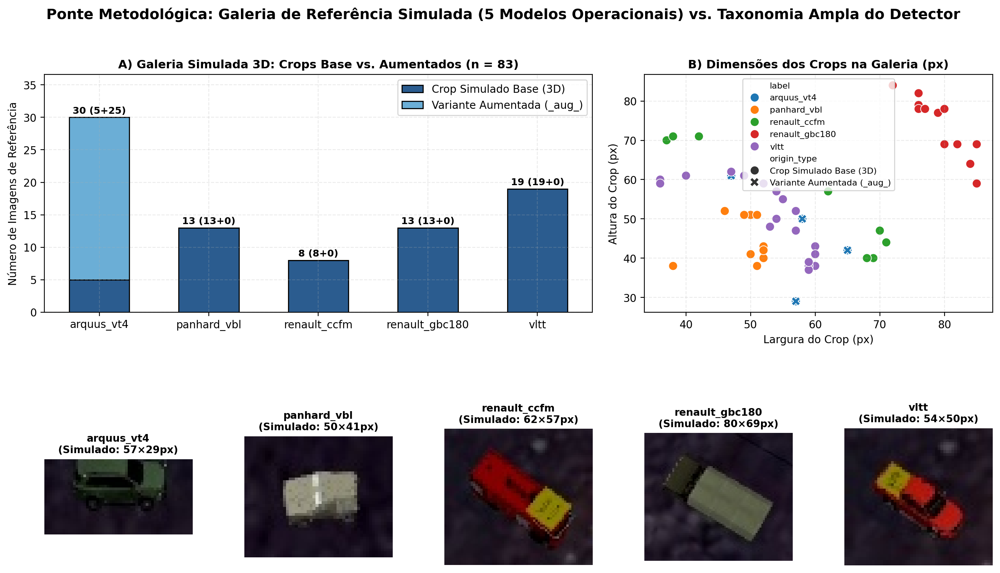

In [8]:
ref_summary_df = pd.DataFrame.from_dict(
    eda_summary["reference_gallery_overview"]["per_class"], orient="index"
).reset_index().rename(columns={"index": "model_label"})
display(ref_summary_df)
display(IPyImage(filename=str(FIG_DIR / "07_reference_gallery_overview.png")))